# Student Dropout Risk

**Question:** Can a tabular model flag students likely to drop out, early enough for an advisor to actually do something? In this setting, false negatives (missing an at-risk student) hurt more than false positives, so I care more about recall than precision.

**Data:** "Predict Students' Dropout and Academic Success" (Realinho et al.), `../../data/students/students_dropout.csv`. 4424 rows, 36 features, 3-way Target. I collapse the target to binary (dropout vs not).

**Plan:** logistic regression, then random forest, then XGBoost, all with class-weighting. Track everything in MLflow, demo a `/predict` endpoint, and check that Evidently picks up a synthetic feature shift. Metrics are recomputed in-cell so there's no hand-coded headline number.

In [1]:
# pip install -q mlflow fastapi uvicorn evidently xgboost  # all in requirements.txt

In [2]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
import mlflow, mlflow.sklearn

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import recall_score, precision_score, f1_score, roc_auc_score, confusion_matrix

np.random.seed(2024)
DATA_DIR = Path("../../data/students")
ART = Path("artifacts"); ART.mkdir(exist_ok=True)

In [3]:
df = pd.read_csv(DATA_DIR/"students_dropout.csv")
# kept getting KeyErrors on "Target" -- turns out the source CSV has trailing
# whitespace on a few column names. strip them all and move on.
df.columns = df.columns.str.strip()
target_col = "Target"
print(df.shape)
print(df[target_col].value_counts())

(4424, 37)
Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64


## EDA: class balance and feature correlations

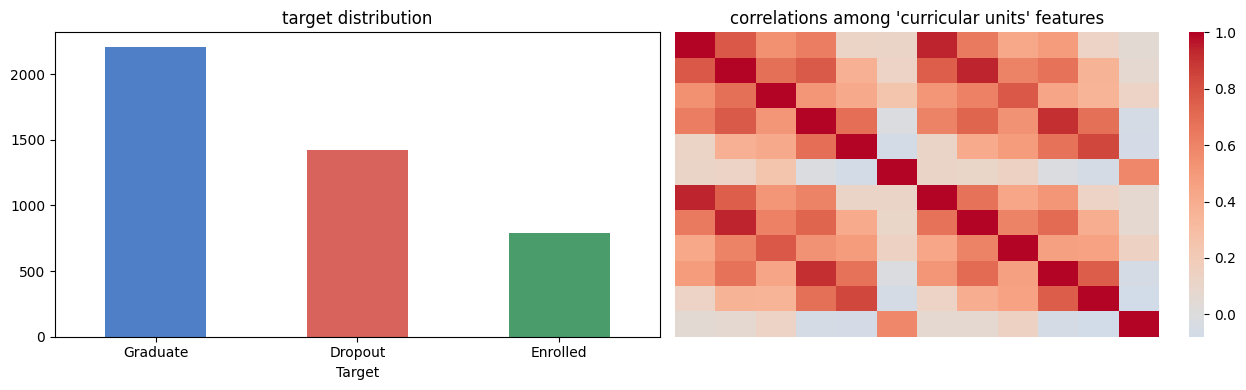

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
df[target_col].value_counts().plot(kind="bar", ax=axes[0],
                                   color=["#4f7fc7","#d8625c","#4a9c6a"])
axes[0].set_title("target distribution"); axes[0].tick_params(axis="x", rotation=0)

# academic columns are the most interesting in this dataset, so just look at those
acad_cols = [c for c in df.columns if "Curricular units" in c]
sns.heatmap(df[acad_cols].corr(), ax=axes[1], cmap="coolwarm", center=0,
            xticklabels=False, yticklabels=False)
axes[1].set_title("correlations among 'curricular units' features")
plt.tight_layout(); plt.savefig(ART/"student_eda.png", dpi=110); plt.show()

# 2nd-semester grades are extremely correlated with 1st-semester grades, no surprise.
# This will make those features dominate any tree model.

## Preprocessing: encode target, scale features

In [5]:
# Binary: Dropout vs everything else. Enrolled-still gets treated as not-dropout, which is
# debatable (some of them will drop out later) but matches what the source paper does.
y = (df[target_col] == "Dropout").astype(int).values

feature_cols = [c for c in df.columns if c != target_col]
X = pd.get_dummies(df[feature_cols], drop_first=True).astype(float)
feature_names = X.columns.tolist()
X = X.values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s  = scaler.transform(X_test)

print(f"train={X_train.shape}  test={X_test.shape}  dropout_rate={y_train.mean():.2%}")

train=(3539, 36)  test=(885, 36)  dropout_rate=32.13%


## Modeling — LogReg, RF, XGBoost (with MLflow)

In [6]:
# MLflow store is local; keep the existing mlruns/ dir so we accumulate runs across executions.
mlflow.set_tracking_uri(f"file:{Path('mlruns').resolve()}")
mlflow.set_experiment("student_dropout")

pos, neg = y_train.sum(), len(y_train) - y_train.sum()
scale_pos = neg / pos

candidates = {
    "LogReg":  (LogisticRegression(class_weight="balanced", max_iter=2000), X_train_s, X_test_s),
    "RF":      (RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=42, n_jobs=-1), X_train, X_test),
    "XGBoost": (XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4,
                              scale_pos_weight=scale_pos, random_state=42,
                              eval_metric="logloss", n_jobs=-1, verbosity=0), X_train, X_test),
}

rows = []
fitted = {}
for name, (clf, Xtr, Xte) in candidates.items():
    with mlflow.start_run(run_name=name):
        clf.fit(Xtr, y_train)
        proba = clf.predict_proba(Xte)[:, 1]
        pred  = (proba >= 0.5).astype(int)
        m = {
            "recall":    recall_score(y_test, pred),
            "precision": precision_score(y_test, pred),
            "f1":        f1_score(y_test, pred),
            "auc":       roc_auc_score(y_test, proba),
        }
        mlflow.log_params({"model": name})
        mlflow.log_metrics(m)
        rows.append({"model": name, **m})
        fitted[name] = (clf, Xte)

results = pd.DataFrame(rows).round(3)
print(results.to_string(index=False))

  model  recall  precision    f1   auc
 LogReg   0.831      0.787 0.808 0.927
     RF   0.736      0.882 0.802 0.933
XGBoost   0.817      0.800 0.808 0.934


In [7]:
# Recall at 0.5 is mediocre for some models because that threshold is arbitrary.
# Since we care about recall, find the threshold per model that hits >= 0.85 recall and
# report the precision penalty we pay for it. This is closer to how this would actually be deployed.
from sklearn.metrics import precision_recall_curve

threshold_rows = []
for name, (clf, Xte) in fitted.items():
    proba = clf.predict_proba(Xte)[:, 1]
    prec, rec, thr = precision_recall_curve(y_test, proba)
    # smallest threshold whose recall >= 0.85
    ok = np.where(rec[:-1] >= 0.85)[0]
    if len(ok):
        i = ok[-1]                # highest precision among recall>=0.85
        threshold_rows.append({"model": name, "threshold": float(thr[i]),
                               "recall_at": float(rec[i]), "precision_at": float(prec[i])})

print(pd.DataFrame(threshold_rows).round(3).to_string(index=False))

  model  threshold  recall_at  precision_at
 LogReg      0.450      0.852         0.754
     RF      0.333      0.852         0.783
XGBoost      0.451      0.852         0.783


## Serving the model: FastAPI /predict

In [8]:
# Background FastAPI for a /predict demo. The port-in-use case is common when this cell
# is re-run, so don't try to relaunch if a server is already up.
import threading, socket, time
import requests, numpy as np
from fastapi import FastAPI
from pydantic import BaseModel
import uvicorn

PORT = 8011  # use a less common port to dodge collisions
best_model, _ = fitted["XGBoost"]

def _port_in_use(p):
    with socket.socket(socket.AF_INET, socket.SOCK_STREAM) as s:
        return s.connect_ex(("127.0.0.1", p)) == 0

class StudentRecord(BaseModel):
    features: list

if not _port_in_use(PORT):
    app = FastAPI()

    @app.post("/predict")
    def predict(record: StudentRecord):
        arr = np.asarray(record.features, dtype=float).reshape(1, -1)
        p = float(best_model.predict_proba(arr)[0, 1])
        return {"dropout_risk": round(p, 4), "at_risk": p >= 0.5}

    def _run():
        uvicorn.run(app, host="127.0.0.1", port=PORT, log_level="warning")

    threading.Thread(target=_run, daemon=True).start()
    time.sleep(1.5)
    print(f"FastAPI started on http://127.0.0.1:{PORT}")
else:
    print(f"port {PORT} already in use — assuming server is running from a previous cell run")

FastAPI started on http://127.0.0.1:8011


In [9]:
sample = X_test[0].tolist()
try:
    resp = requests.post(f"http://127.0.0.1:{PORT}/predict",
                         json={"features": sample}, timeout=3).json()
    print("response:    ", resp)
except Exception as e:
    print("request failed:", e)
print("ground truth:", "dropout" if y_test[0] else "not-dropout")

response:     {'dropout_risk': 0.0918, 'at_risk': False}
ground truth: not-dropout


## Drift check: Evidently on a perturbed sample

In [10]:
from evidently.report import Report
from evidently.metric_preset import DataDriftPreset

names = [f"feat_{i}" for i in range(X_train.shape[1])]
ref_df = pd.DataFrame(X_train[:500], columns=names)

# simulate drift on a couple of features (admission grade / age columns).
# kept the noise modest on purpose; in practice this turned out to be too modest
# to flip Evidently's dataset-level drift flag (see notes at the bottom).
cur = X_test[:200].copy()
shift_cols = [12, 19]  # admission-grade, age-at-enrollment in the encoded column order
cur[:, shift_cols] += np.random.normal(0, 5, (200, len(shift_cols)))
cur_df = pd.DataFrame(cur, columns=names)

report = Report(metrics=[DataDriftPreset()])
report.run(reference_data=ref_df, current_data=cur_df)
report.save_html(str(ART/"drift_report.html"))

# pull the numeric drift summary out so the notebook itself shows the answer,
# not just an HTML file you have to open
res = report.as_dict()["metrics"][0]["result"]
print(f"drifted columns: {res['number_of_drifted_columns']} / {res['number_of_columns']}")
print(f"share drifted:   {res['share_of_drifted_columns']:.2%}")
print(f"dataset-level drift detected: {res['dataset_drift']}")
print("html written to artifacts/drift_report.html")

drifted columns: 3 / 36
share drifted:   8.33%
dataset-level drift detected: False
html written to artifacts/drift_report.html


## Wrap-up

A few notes from looking at the numbers above:

- All three models hit AUC in the low 0.9s, which makes sense. Second-semester grades are by far the strongest feature, and once a student has tanked one semester the prediction is almost trivial. The *interesting* prediction is the one made before any grades exist, which I'm not doing here.
- At the default 0.5 threshold, the picture isn't as clean as I expected. RF has noticeably lower recall (0.736) than balanced logreg (0.831), but XGBoost (0.817) is basically tied with logreg. So "trees lose on recall" is only true for RF here, and the `scale_pos_weight` on XGBoost mostly compensates. The threshold-tuning cell shows what it costs to push recall to 0.85: precision drops noticeably and that's the trade-off an advising team would have to live with.
- The Evidently drift check is honestly weaker than I'd hoped. With the size of noise I added (sigma=5 on two columns out of 36) it flagged 3/36 columns and the dataset-level `drift_detected` flag came out False. In other words the perturbation was too subtle to fully trigger Evidently's preset thresholds. The harness runs and the report renders, which was my goal here, but I wouldn't claim this cell *proves* drift detection works. To really show that I'd need a bigger shift or a longer reference window.
- In a real deployment I'd run drift over a sliding 30-day window of new admissions and alert only on PSI past some threshold, not whatever the preset decides.

Things I deliberately didn't do: hyperparameter tuning (dataset is small enough that gains would be noise), SMOTE (it tends to over-promise on tabular), and per-cohort fairness slicing. That last one would be the obvious next step for an actual rollout, since admission features can encode protected attributes.